In [1]:
!git clone https://github.com/sashaLitv/Quantum-Test-Tasks.git

Cloning into 'Quantum-Test-Tasks'...
remote: Enumerating objects: 185, done.
remote: Counting objects: 100% (185/185), done.
remote: Compressing objects: 100% (122/122), done.
remote: Total 185 (delta 82), reused 153 (delta 52), pack-reused 0 (from 0)
Receiving objects: 100% (185/185), 11.29 MiB | 36.82 MiB/s, done.
Resolving deltas: 100% (82/82), done.


In [2]:
## delete unnecessary
!rm -rf "/kaggle/working/Quantum-Test-Tasks/Natural Language Processing. Named entity recognition"
!rm -rf "/kaggle/working/Quantum-Test-Tasks/.git"

In [3]:
import os
target_dir = '/kaggle/working/Quantum-Test-Tasks/Computer vision. Sentinel-2 image matching'
os.chdir(target_dir)

In [4]:
import sys

target_dir = "/kaggle/working/Quantum-Test-Tasks/Computer vision. Sentinel-2 image matching/src"
sys.path.insert(0, target_dir)

In [5]:
import re
from collections import defaultdict

location_groups = defaultdict(list)

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('_TCI.jp2'):
            full_path = os.path.join(dirname, filename)
            
            match = re.search(r'_(T\d{2}[A-Z]{3})_', full_path)
            
            if match:
                tile_id = match.group(1) 
                location_groups[tile_id].append(full_path)

print(f"Unique location: {len(location_groups)} (Tiles: {list(location_groups.keys())})")

Unique location: 2 (Tiles: ['T36UYA', 'T36UXA'])


In [6]:
import random
import itertools

random.seed(42)


flat_dataset = []
for tile_id, paths in location_groups.items():
    for path in paths:
        flat_dataset.append({'path': path, 'tile_id': tile_id})

all_possible_pairs = list(itertools.combinations(flat_dataset, 2))


intra_location_pairs = [
    (p1['path'], p2['path'])
    for p1, p2 in all_possible_pairs
    if p1['tile_id'] == p2['tile_id']
]

cross_location_pairs = [
    (p1['path'], p2['path'])
    for p1, p2 in all_possible_pairs
    if p1['tile_id'] != p2['tile_id']
]


n_samples = 6
sampled_intra = random.sample(
    intra_location_pairs, min(n_samples, len(intra_location_pairs))
)
sampled_cross = random.sample(
    cross_location_pairs, min(n_samples, len(cross_location_pairs))
)

image_pairs = sampled_intra + sampled_cross

In [7]:
import torch

print("GPU availability:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU availability: True
GPU: Tesla T4


In [8]:
!pip3 install kornia kornia_moons rasterio

Downloading: "http://cmp.felk.cvut.cz/~mishkdmy/models/loftr_outdoor.ckpt" to /root/.cache/torch/hub/checkpoints/loftr_outdoor.ckpt


100%|██████████| 44.2M/44.2M [00:03<00:00, 15.3MB/s]


 RESULT
  overlap confidence .............. 0.998  (HIGH — likely the same location)
  inliers ......................... 31495
  total matches ................... 32973
  alignment ....................... OK (aligned)


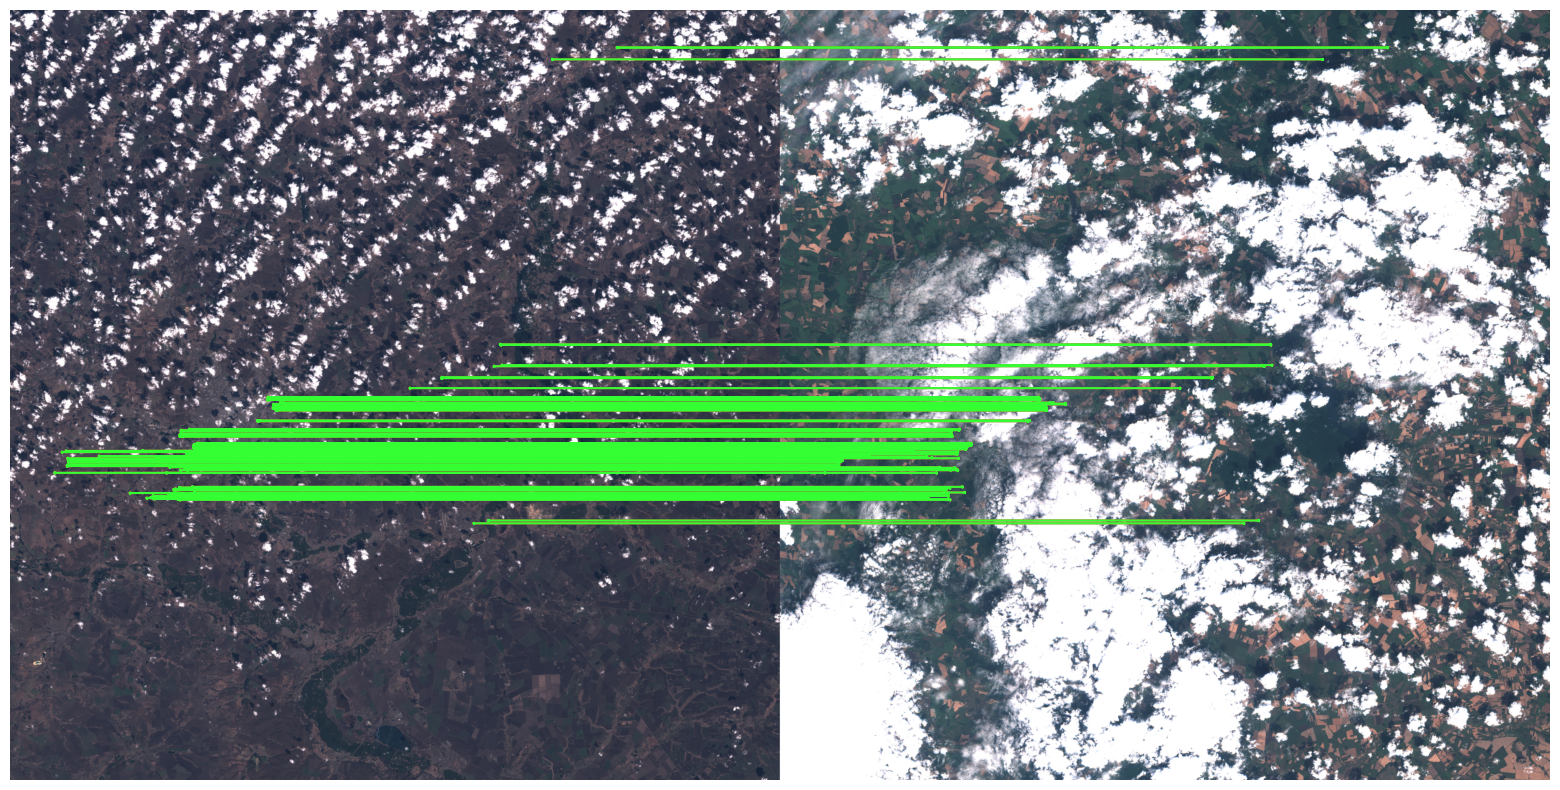

In [9]:
import kornia 
from algorithm_creation import AlgorithmConfig, InferenceEngine, GlobalAligner, ImagePreprocessor, SatelliteMatcher
from model_inference import MatchingPipeline

## one test with visualization
config = AlgorithmConfig(
    tile_size=512,
    device='cuda',
    min_matches=4
)

feature_extractor = kornia.feature.LoFTR(pretrained='outdoor').to(config.device)
engine = InferenceEngine(feature_extractor, config)
pipeline = MatchingPipeline(engine, config, output=True)

result = pipeline(image_pairs[0][0], image_pairs[0][1])

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best" 
)

In [10]:
# Process sequential pairs images in dataset 
## evaluate raw LoFTR matches using the USAC_MAGSAC algorithm to filter outliers and 
## calculate the exact number of true inliers.
import numpy as np
from concurrent.futures import ThreadPoolExecutor 

def process_pairs(pairs, device):
    config = AlgorithmConfig(device=device, tile_size=512, ransac_threshold=3.0)
    feature_extractor = kornia.feature.LoFTR(pretrained='outdoor').to(config.device)
    engine = InferenceEngine(feature_extractor, config)
    
    pipeline = MatchingPipeline(engine, config, output=False) 
    statistics = []

    for idx, (img1, img2) in pairs:
        try:
            result = pipeline(img1, img2)

            if result.is_empty:
                statistics.append({
                    'pair_index': idx,
                    'img1': os.path.basename(img1),
                    'img2': os.path.basename(img2),
                    'overlap_confidence': 0.0
                    
                })
                continue
            
            statistics.append({
                'pair_index': idx,
                'img1': result.image_path0,
                'img2': result.image_path1,
                'overlap_confidence': result.overlap_confidence
            })

        except Exception as e:
            print(f"Pair {idx}: {e}")

    return statistics

indexed_pairs = list(enumerate(image_pairs))
mid = len(indexed_pairs) // 2

pairs_gpu0 = indexed_pairs[:mid]
pairs_gpu1 = indexed_pairs[mid:]

with ThreadPoolExecutor(max_workers=2) as executor:
    future0 = executor.submit(process_pairs, pairs_gpu0, "cuda:0")
    future1 = executor.submit(process_pairs, pairs_gpu1, "cuda:1")

    all_statistics = future0.result() + future1.result()

all_statistics.sort(key=lambda x: x["pair_index"])

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, classification_report
)

df = pd.DataFrame(all_statistics)

print("Columns:", list(df.columns))
print("Rows:", len(df))
print(df["overlap_confidence"].describe())

THRESHOLD_MATCH = 0.5

def classify(conf):
    if conf > THRESHOLD_MATCH:
        return "match"
    return "no_match"

df["prediction"] = df["overlap_confidence"].apply(classify)

print("\nPrediction counts:")
print(df["prediction"].value_counts())

Columns: ['pair_index', 'img1', 'img2', 'overlap_confidence']
Rows: 12
count    12.000000
mean      0.557979
std       0.488794
min       0.009591
25%       0.015020
50%       0.823837
75%       0.997660
max       0.999902
Name: overlap_confidence, dtype: float64

Prediction counts:
prediction
match       7
no_match    5
Name: count, dtype: int64


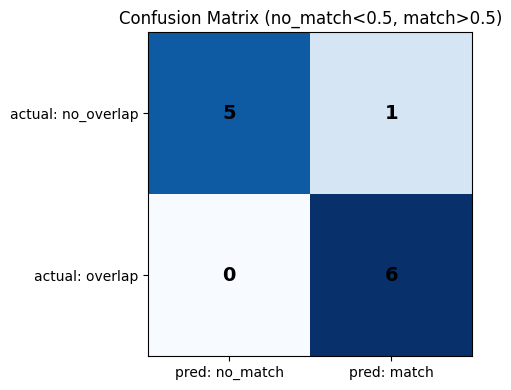

In [12]:
def tile_id(name):
    m = re.search(r"_(T\d{2}[A-Z]{3})_", name)
    return m.group(1) if m else None

df["tile0"] = df["img1"].apply(tile_id)
df["tile1"] = df["img2"].apply(tile_id)
df["truth"] = (df["tile0"] == df["tile1"]) & df["tile0"].notna()

# Confusion matrix
y_true = df["truth"].to_numpy(dtype=bool)
y_pred = (df["prediction"] == "match").to_numpy(dtype=bool)

# labels=[False, True] -> rows/cols ordered [negative, positive] => [[TN FP],[FN TP]]
cm = confusion_matrix(y_true, y_pred, labels=[False, True])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=["pred: no_match", "pred: match"])
ax.set_yticks([0, 1], labels=["actual: no_overlap", "actual: overlap"])
ax.set_title(f"Confusion Matrix (no_match<{THRESHOLD_MATCH}, match>{THRESHOLD_MATCH})")
for r in range(2):
    for c in range(2):
        ax.text(c, r, cm[r, c], ha="center", va="center",
                color="black", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


In [13]:
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)

print(f"\nAccuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")
print("\nFull report:")
print(classification_report(y_true, y_pred, labels=[False, True],
                            target_names=["no_overlap", "overlap"], zero_division=0))


Accuracy : 0.917
Precision: 0.857
Recall   : 1.000
F1-score : 0.923

Full report:
              precision    recall  f1-score   support

  no_overlap       1.00      0.83      0.91         6
     overlap       0.86      1.00      0.92         6

    accuracy                           0.92        12
   macro avg       0.93      0.92      0.92        12
weighted avg       0.93      0.92      0.92        12

